# 07. Análisis de Monitoreo, Ética Operativa, Criterios de Retirada y Resultado de Negocio

**Proyecto Final (PSet #4 — Secciones 6, 8 y 9):**
- Diagnóstico formal de deriva de datos vs. deriva conceptual y análisis de falsas alarmas estacionales (`L12_202512`).
- **Ética Operativa (Sección 8):** evaluación de equidad y desempeño por subgrupos (`SECTOR_MACRO` y tamaño económico de rama CIIU), análisis de quién asume el costo de cada tipo de error (sobreestimación vs. subestimación), **3 criterios observables de retirada** y revisión del juicio humano del PSet #1.
- **Resultado de Negocio (Sección 9):** comparación lote por lote frente a la línea base de negocio (`HeuristicaBCE`, proceso actual) y frente a *"no hacer nada"* (`Dummy`), cuantificando el efecto del reentrenamiento (`v1` $\rightarrow$ `v4`) y respondiendo la pregunta del PSet #1.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.datos import preparar_universo_nowcasting, dividir_train_test
from src.pipeline import agregar_features, OBJETIVO, calcular_metricas, HeuristicaBCE

DOCS_DIR = ROOT_DIR / 'docs'
FIG_DIR = DOCS_DIR / 'figuras'
FIG_DIR.mkdir(parents=True, exist_ok=True)

df_pred = pd.read_csv(DOCS_DIR / 'predicciones.csv')
df_mon = pd.read_csv(DOCS_DIR / 'monitoreo.csv')
df_al = pd.read_csv(DOCS_DIR / 'alertas.csv')
df_reent = pd.read_csv(DOCS_DIR / 'reentrenamientos.csv')

universo = agregar_features(preparar_universo_nowcasting(forzar_snowflake=False))
train_df, test_df = dividir_train_test(universo)
test_12m = test_df[test_df['TIEMPO_KEY'] <= 202512].copy()
test_12m['CODIGO_INDUSTRIA'] = test_12m['CODIGO_INDUSTRIA'].apply(lambda x: f'{int(x):03d}')
df_pred['CODIGO_INDUSTRIA'] = df_pred['CODIGO_INDUSTRIA'].apply(lambda x: f'{int(x):03d}')

df_unido = df_pred.merge(
    test_12m[['CODIGO_INDUSTRIA', 'TIEMPO_KEY', 'NOMBRE_INDUSTRIA', 'SECTOR_MACRO', 'SECTOR_ECONOMICO', OBJETIVO, 'proyeccion_cobertura_12m']],
    on=['CODIGO_INDUSTRIA', 'TIEMPO_KEY'],
    how='left'
)
print('Filas unidas (predicciones + ground truth definitivo):', len(df_unido))

Filas unidas (predicciones + ground truth definitivo): 552


## 1. Diagnóstico de Deriva y Tabla de Alertas Disparadas (Secciones 6.2 y 6.3)

In [2]:
display(df_mon[['LOTE_ID', 'VERSION_MODELO', 'PSI_MAX_NUCLEAR', 'FEATURE_MAX_PSI', 'KS_MIN_PVALUE',
                'MAE_LOTE', 'WAPE_LOTE_PCT', 'DIAGNOSTICO_DERIVA', 'ACCION_RECOMENDADA']])
print('\n=== Alertas Registradas en PSET2_DB.ANALYTICS.ALERTAS ===')
display(df_al)

,LOTE_ID,VERSION_MODELO,PSI_MAX_NUCLEAR,FEATURE_MAX_PSI,KS_MIN_PVALUE,MAE_LOTE,WAPE_LOTE_PCT,DIAGNOSTICO_DERIVA,ACCION_RECOMENDADA
0,L01_202501,1,0.0752,INDICE_PRECIO_REAL,0.622623,15.3840,3.9581,Estable,Mantener modelo @champion actual en producción
1,L02_202502,1,0.1193,INDICE_PRECIO_REAL,0.117210,12.7338,3.3363,Estable,Mantener modelo @champion actual en producción
2,L03_202503,1,0.2265,INDICE_PRECIO_REAL,0.124004,17.0083,4.2386,Estable,Mantener modelo @champion actual en producción
3,L04_202504,1,0.0840,proyeccion_cobertura_12m,0.272606,12.0703,2.8823,Estable,Mantener modelo @champion actual en producción
4,L05_202505,1,0.0903,INDICE_PRECIO_REAL,0.327505,13.2556,3.1014,Estable,Mantener modelo @champion actual en producción
5,L06_202506,1,0.2282,VENTAS_NOMINALES_USD,0.010957,20.6601,3.8920,Estable,Mantener modelo @champion actual en producción
6,L07_202507,1,0.0990,proyeccion_cobertura_12m,0.246711,8.6953,2.0594,Estable,Mantener modelo @champion actual en producción
7,L08_202508,1,0.2010,proyeccion_cobertura_12m,0.128586,10.4542,2.5284,Estable,Mantener modelo @champion actual en producción
8,L09_202509,1,0.0790,proyeccion_cobertura_12m,0.319150,7.9964,1.8194,Estable,Mantener modelo @champion actual en producción
9,L10_202510_DERIVA,1,7.3498,INDICE_PRECIO_REAL,0.000000,230.2252,51.1379,Deriva de datos con impacto,Auditar fuente SRI/precios y disparar reentren...



=== Alertas Registradas en PSET2_DB.ANALYTICS.ALERTAS ===


,ID_ALERTA,TIMESTAMP_UTC,LOTE_ID,TIEMPO_KEY,METRICA,VALOR_OBSERVADO,UMBRAL,VENTA_EVALUACION,SEVERIDAD,QUIEN_LA_RECIBE,ACCION,DISPARA_REENTRENAMIENTO
0,29cec66cdc194e94,2026-11-19T19:06:51Z,L10_202510_DERIVA,202510,PSI de INDICE_PRECIO_REAL,7.3498,>= 0.25,1 lote,Media,Analista de Precios / SCNC,Verificar choque inflacionario en índice secto...,False
1,375c59605d1a4948,2026-11-19T19:06:51Z,L10_202510_DERIVA,202510,MAE del lote (degradación de desempeño),230.2252,> 16.14 M USD (MAE_CV + 2*std),1 lote crítico o 2 lotes consecutivos,Crítica,Comité Técnico MLOps / SCNC,Disparar flujo Kestra reentrenamiento.yml y ev...,True
2,ff97dba637e64053,2026-11-19T19:06:51Z,L10_202510_DERIVA,202510,PSI de proyeccion_cobertura_12m,0.3358,>= 0.25,1 lote,Alta,Equipo de Datos / SCNC,Revisar fuente F104 SRI y evaluar reentrenamie...,False
3,66e1b5854ff94d82,2026-11-19T19:07:01Z,L12_202512,202512,PSI de VENTAS_NOMINALES_USD,0.2694,>= 0.25,1 lote,Alta,Equipo de Datos / SCNC,Auditar cobertura del corte temprano día 15 en...,False
4,f43c707c8b7946fc,2026-11-19T19:07:01Z,L12_202512,202512,PSI de proyeccion_cobertura_12m,0.3373,>= 0.25,1 lote,Alta,Equipo de Datos / SCNC,Revisar fuente F104 SRI y evaluar reentrenamie...,False


## 2. Ética Operativa: Desempeño y Tasa de Decisión por Subgrupo (Sección 8.1)

Evaluamos los 11 lotes limpios de operación normal (`506` predicciones rama-mes, excluyendo el choque sintético `L10_202510_DERIVA`) desagregados por:
1. **Macrosector Económico (`SECTOR_MACRO`, 8 subgrupos CIIU).**
2. **Escala Económica de la Rama (`Tamano_Rama`: Grandes $>500\text{ M USD/mes}$, Medianas $100\text{--}500\text{ M}$, Pequeñas $<100\text{ M}$).**

In [3]:
df_limpio = df_unido[df_unido['LOTE_ID'] != 'L10_202510_DERIVA'].copy()

filas_sub = []
for sector, grp in df_limpio.groupby('SECTOR_MACRO'):
    m = calcular_metricas(grp[OBJETIVO], grp['PREDICCION_VENTAS_MUSD'])
    m_bce = calcular_metricas(grp[OBJETIVO], grp['proyeccion_cobertura_12m'])
    decs = grp['DECISION'].value_counts(normalize=True)
    filas_sub.append({
        'SECTOR_MACRO': sector,
        'Ramas_x_Mes': len(grp),
        'Ventas_Medias_MUSD': round(float(grp[OBJETIVO].mean()), 2),
        'MAE_MUSD': round(m['mae'], 2),
        'WAPE_PCT': round(m['wape_pct'], 2),
        'Costo_Modelo_MUSD': round(m['costo_negocio_musd'], 2),
        'Costo_BCE_MUSD': round(m_bce['costo_negocio_musd'], 2),
        'Tasa_Expansion_PCT': round(float(decs.get('publicar_flash_expansion', 0.0) * 100), 1),
        'Tasa_Estable_PCT': round(float(decs.get('publicar_flash_estable', 0.0) * 100), 1),
        'Tasa_Contraccion_PCT': round(float(decs.get('alerta_contraccion_comite', 0.0) * 100), 1),
    })
df_subgrupos = pd.DataFrame(filas_sub).sort_values('Ventas_Medias_MUSD', ascending=False)
display(df_subgrupos)

# Desempeño por tamaño de rama
medias_rama = df_limpio.groupby('CODIGO_INDUSTRIA')[OBJETIVO].mean()
mapa_tam = medias_rama.apply(lambda v: '1. Grandes (>500 M USD)' if v > 500 else ('2. Medianas (100-500 M USD)' if v >= 100 else '3. Pequeñas (<100 M USD)')).to_dict()
df_limpio['Tamano_Rama'] = df_limpio['CODIGO_INDUSTRIA'].map(mapa_tam)
filas_tam = []
for tam, grp in df_limpio.groupby('Tamano_Rama'):
    m = calcular_metricas(grp[OBJETIVO], grp['PREDICCION_VENTAS_MUSD'])
    filas_tam.append({
        'Segmento_Tamano': tam,
        'Observaciones': len(grp),
        'MAE_MUSD': round(m['mae'], 2),
        'WAPE_PCT': round(m['wape_pct'], 2),
        'Costo_Modelo_MUSD': round(m['costo_negocio_musd'], 2),
    })
display(pd.DataFrame(filas_tam).sort_values('Segmento_Tamano'))

,SECTOR_MACRO,Ramas_x_Mes,Ventas_Medias_MUSD,MAE_MUSD,WAPE_PCT,Costo_Modelo_MUSD,Costo_BCE_MUSD,Tasa_Expansion_PCT,Tasa_Estable_PCT,Tasa_Contraccion_PCT
1,Comercio,11,8459.34,98.37,1.16,139.29,143.95,100.0,0.0,0.0
6,Servicios empresariales y otros servicios,88,508.33,15.60,3.07,18.83,20.29,63.6,14.8,21.6
2,Construccion,11,479.53,20.94,4.37,25.83,26.77,63.6,18.2,18.2
3,Electricidad y agua,11,467.63,18.36,3.93,24.62,29.08,72.7,0.0,27.3
5,Petroleo y minas,22,262.41,18.85,7.18,24.52,27.86,59.1,13.6,27.3
0,"Agricultura, ganaderia, silvicultura y pesca",77,262.04,8.33,3.18,9.28,9.81,84.4,7.8,7.8
7,Servicios sociales y administracion publica,33,247.69,20.75,8.38,27.05,29.50,63.6,24.2,12.1
4,Manufactura,253,183.27,9.82,5.36,11.91,12.48,49.8,6.3,13.4


,Segmento_Tamano,Observaciones,MAE_MUSD,WAPE_PCT,Costo_Modelo_MUSD
0,1. Grandes (>500 M USD),66,34.36,1.64,45.68
1,2. Medianas (100-500 M USD),330,12.68,4.93,15.29
2,3. Pequeñas (<100 M USD),110,6.02,12.41,7.68


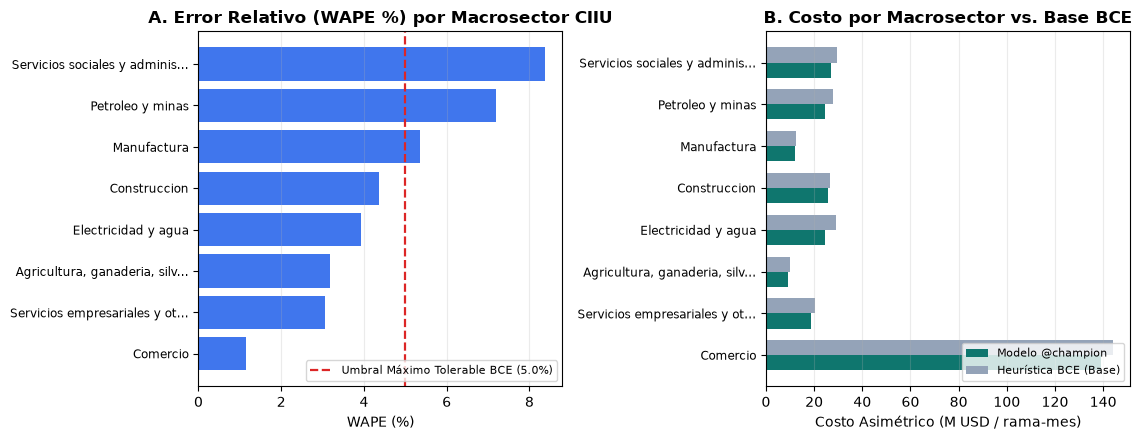

Figura guardada en: D:\Maestria Ciencia de Datos\asignatures\3_data_science\3_1_homeworks\proyecto_final\docs\figuras\07_etica_subgrupos.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))

df_plot = df_subgrupos.sort_values('WAPE_PCT', ascending=True)
etiquetas_sec = [s[:28] + '...' if len(s) > 28 else s for s in df_plot['SECTOR_MACRO']]
y_pos = np.arange(len(df_plot))

axes[0].barh(y_pos, df_plot['WAPE_PCT'], color='#2563eb', alpha=0.88)
axes[0].axvline(5.0, color='#dc2626', linestyle='--', linewidth=1.6, label='Umbral Máximo Tolerable BCE (5.0%)')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(etiquetas_sec, fontsize=8.5)
axes[0].set_xlabel('WAPE (%)')
axes[0].set_title('A. Error Relativo (WAPE %) por Macrosector CIIU', fontweight='bold')
axes[0].legend(loc='lower right', fontsize=8)
axes[0].grid(True, axis='x', alpha=0.25)

ancho = 0.36
axes[1].barh(y_pos - ancho/2, df_plot['Costo_Modelo_MUSD'], height=ancho, color='#0f766e', label='Modelo @champion')
axes[1].barh(y_pos + ancho/2, df_plot['Costo_BCE_MUSD'], height=ancho, color='#94a3b8', label='Heurística BCE (Base)')
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(etiquetas_sec, fontsize=8.5)
axes[1].set_xlabel('Costo Asimétrico (M USD / rama-mes)')
axes[1].set_title('B. Costo por Macrosector vs. Base BCE', fontweight='bold')
axes[1].legend(loc='lower right', fontsize=8)
axes[1].grid(True, axis='x', alpha=0.25)

fig.tight_layout()
fig.savefig(FIG_DIR / '07_etica_subgrupos.png', dpi=220)
plt.show()
print('Figura guardada en:', FIG_DIR / '07_etica_subgrupos.png')

## 3. Resultado de Negocio Lote por Lote (Sección 9)

Comparamos el costo asimétrico de negocio ($1.5\times$ sobreestimación, $1.0\times$ subestimación, en M USD reales por rama-mes y agregado nacional sobre las 46 ramas) entre:
1. **Modelo en producción (`@champion` v1 en L01–L10 y `@champion` v4 en L11–L12 tras el reentrenamiento).**
2. **Línea base de negocio (`HeuristicaBCE`, extrapolación por cobertura histórica 12m).**
3. **No hacer nada (`DummyRegressor` mediana histórica / esperar 45 días sin IMAEC Flash).**

In [5]:
tabla_negocio = df_mon[[
    'LOTE_ID', 'VERSION_MODELO', 'COSTO_NEGOCIO_LOTE_MUSD',
    'COSTO_HEURISTICA_BCE_MUSD', 'COSTO_DUMMY_NO_HACER_NADA_MUSD', 'AHORRO_VS_HEURISTICA_MUSD'
]].copy()
tabla_negocio['AHORRO_AGREGADO_46_RAMAS_MUSD'] = (tabla_negocio['AHORRO_VS_HEURISTICA_MUSD'] * 46.0).round(2)
display(tabla_negocio.round(3))

limpios_mon = tabla_negocio[tabla_negocio['LOTE_ID'] != 'L10_202510_DERIVA']
costo_medio_mod_limpio = float(limpios_mon['COSTO_NEGOCIO_LOTE_MUSD'].mean())
costo_medio_bce_limpio = float(limpios_mon['COSTO_HEURISTICA_BCE_MUSD'].mean())
costo_medio_dummy_limpio = float(limpios_mon['COSTO_DUMMY_NO_HACER_NADA_MUSD'].mean())
ahorro_total_11_lotes = float(limpios_mon['AHORRO_AGREGADO_46_RAMAS_MUSD'].sum())
ahorro_total_12_lotes = float(tabla_negocio['AHORRO_AGREGADO_46_RAMAS_MUSD'].sum())

print(f'=== RESUMEN EJECUTIVO DE RESULTADO DE NEGOCIO ===')
print(f'1. En los 11 lotes limpios (506 predicciones):')
print(f'   - Costo medio Modelo @champion : {costo_medio_mod_limpio:.2f} M USD/rama-mes')
print(f'   - Costo medio Heurística BCE   : {costo_medio_bce_limpio:.2f} M USD/rama-mes')
print(f'   - Costo medio No Hacer Nada    : {costo_medio_dummy_limpio:.2f} M USD/rama-mes')
print(f'   - Ahorro neto acumulado vs BCE : {ahorro_total_11_lotes:+.2f} M USD reales (46 ramas x 11 meses)')
print(f'2. Incluyendo el Lote 10 con choque SRI (-40% ventas tempranas):')
print(f'   - Ahorro neto acumulado 12 lotes vs BCE: {ahorro_total_12_lotes:+.2f} M USD reales (el modelo amortigua mejor el choque que la extrapolación simple de HeuristicaBCE)')

,LOTE_ID,VERSION_MODELO,COSTO_NEGOCIO_LOTE_MUSD,COSTO_HEURISTICA_BCE_MUSD,COSTO_DUMMY_NO_HACER_NADA_MUSD,AHORRO_VS_HEURISTICA_MUSD,AHORRO_AGREGADO_46_RAMAS_MUSD
0,L01_202501,1,18.328,18.905,313.635,0.577,26.55
1,L02_202502,1,14.874,15.234,309.281,0.359,16.53
2,L03_202503,1,22.889,23.682,328.906,0.794,36.50
3,L04_202504,1,15.432,16.629,337.485,1.197,55.07
4,L05_202505,1,16.828,17.798,346.628,0.970,44.60
5,L06_202506,1,26.734,26.762,433.793,0.027,1.26
6,L07_202507,1,11.182,12.370,339.582,1.188,54.62
7,L08_202508,1,13.456,14.288,331.984,0.832,38.28
8,L09_202509,1,9.561,11.109,354.700,1.548,71.20
9,L10_202510_DERIVA,1,230.229,240.134,361.906,9.905,455.61


=== RESUMEN EJECUTIVO DE RESULTADO DE NEGOCIO ===
1. En los 11 lotes limpios (506 predicciones):
   - Costo medio Modelo @champion : 17.60 M USD/rama-mes
   - Costo medio Heurística BCE   : 18.74 M USD/rama-mes
   - Costo medio No Hacer Nada    : 367.52 M USD/rama-mes
   - Ahorro neto acumulado vs BCE : +578.97 M USD reales (46 ramas x 11 meses)
2. Incluyendo el Lote 10 con choque SRI (-40% ventas tempranas):
   - Ahorro neto acumulado 12 lotes vs BCE: +1034.58 M USD reales (el modelo amortigua mejor el choque que la extrapolación simple de HeuristicaBCE)


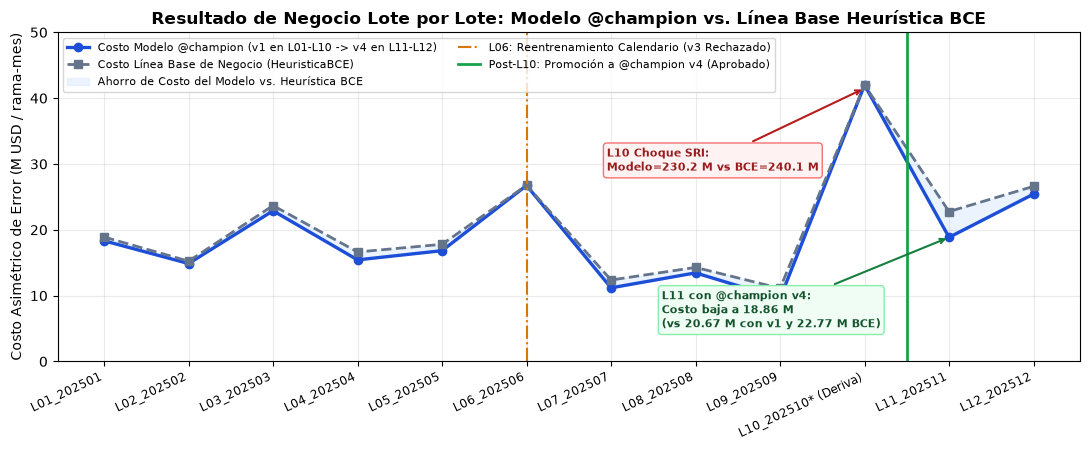

Figura guardada en: D:\Maestria Ciencia de Datos\asignatures\3_data_science\3_1_homeworks\proyecto_final\docs\figuras\07_resultado_negocio_lotes.png


In [6]:
fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(df_mon))
etiquetas = df_mon['LOTE_ID'].str.replace('_DERIVA', '* (Deriva)', regex=False)

# Acotar visualmente L10 para apreciar la comparación en los 11 lotes operativos y anotar L10
c_mod = np.minimum(df_mon['COSTO_NEGOCIO_LOTE_MUSD'], 42.0)
c_bce = np.minimum(df_mon['COSTO_HEURISTICA_BCE_MUSD'], 42.0)

ax.plot(x, c_mod, marker='o', linewidth=2.4, color='#1d4ed8', label='Costo Modelo @champion (v1 en L01-L10 -> v4 en L11-L12)')
ax.plot(x, c_bce, marker='s', linewidth=2.0, linestyle='--', color='#64748b', label='Costo Línea Base de Negocio (HeuristicaBCE)')
ax.fill_between(x, c_mod, c_bce, where=(c_bce >= c_mod), color='#dbeafe', alpha=0.55, label='Ahorro de Costo del Modelo vs. Heurística BCE')

ax.axvline(5, color='#d97706', linestyle='-.', linewidth=1.5, label='L06: Reentrenamiento Calendario (v3 Rechazado)')
ax.axvline(9.5, color='#16a34a', linestyle='-', linewidth=2.0, label='Post-L10: Promoción a @champion v4 (Aprobado)')

ax.annotate(
    f'L10 Choque SRI:\nModelo={df_mon.loc[9, "COSTO_NEGOCIO_LOTE_MUSD"]:.1f} M vs BCE={df_mon.loc[9, "COSTO_HEURISTICA_BCE_MUSD"]:.1f} M',
    xy=(9, 41.5), xytext=(5.95, 29.0),
    arrowprops={'arrowstyle': '->', 'color': '#b91c1c', 'lw': 1.5},
    fontsize=8.2, fontweight='bold', color='#991b1b',
    bbox={'boxstyle': 'round,pad=0.3', 'facecolor': '#fef2f2', 'edgecolor': '#f87171'}
)
ax.annotate(
    'L11 con @champion v4:\nCosto baja a 18.86 M\n(vs 20.67 M con v1 y 22.77 M BCE)',
    xy=(10, df_mon.loc[10, 'COSTO_NEGOCIO_LOTE_MUSD']), xytext=(6.6, 5.2),
    arrowprops={'arrowstyle': '->', 'color': '#15803d', 'lw': 1.5},
    fontsize=8.2, fontweight='bold', color='#14532d',
    bbox={'boxstyle': 'round,pad=0.3', 'facecolor': '#f0fdf4', 'edgecolor': '#86efac'}
)

ax.set_ylabel('Costo Asimétrico de Error (M USD / rama-mes)')
ax.set_ylim(0, 50)
ax.set_xticks(x)
ax.set_xticklabels(etiquetas, rotation=25, ha='right', fontsize=8.5)
ax.set_title('Resultado de Negocio Lote por Lote: Modelo @champion vs. Línea Base Heurística BCE', fontweight='bold')
ax.legend(loc='upper left', fontsize=7.8, ncol=2)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / '07_resultado_negocio_lotes.png', dpi=220)
plt.show()
print('Figura guardada en:', FIG_DIR / '07_resultado_negocio_lotes.png')